# Ubicar un puntaje publicado en la distribución de su propio protocolo: el 0,943 del conjunto de apilamiento

**Nivel 3: Estado del arte** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts, 04-benchmark-protocol/02-scores-the-null-and-the-interval · Tiempo de lectura: unos 30 minutos

## Objetivos

El predictor publicado más reciente sobre este corpus es un conjunto de apilamiento informado con una varianza explicada de 0,943. La cifra viene de una sola división aleatoria 80/20. Este notebook hace la pregunta que un solo número no puede responder: ¿dónde cae 0,943 entre los puntajes que el mismo protocolo da en otros sorteos, y qué pasa con el puntaje cuando se deja fuera la campaña?

Al terminar habrá:

- reajustado el conjunto de apilamiento y la regresión de vectores de soporte de núcleo polinómico en 100 sorteos aleatorios 80/20 y ubicado cada cifra publicada en la distribución de su propio protocolo;
- repetido los sorteos tras colapsar los vectores de entrada duplicados, para probar si los duplicados explican la brecha;
- medido la brecha entre la mediana de la división aleatoria y el puntaje con un sitio fuera, y coincidido con el benchmark versionado.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del notebook: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este notebook
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los puntajes publicados 0,943 (apilamiento) y 0,578 (vectores de soporte, polinómico) | Sui et al. 2025, https://doi.org/10.3390/app15031254 | hechos numéricos reutilizados con cita (acceso abierto, CC BY) | `bf.PUBLISHED_RANDOM_SPLIT_R2` dentro del paquete `blastfrag` |
| Las distribuciones y el veredicto versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campos `protocols` y `verdict` |

## Método

Para un brazo y un protocolo, el motor produce un puntaje por sorteo. La cifra publicada se ubica luego en esa distribución: la parte de sorteos que queda bajo ella dice si es un resultado típico del protocolo o uno favorable. Solo se ubican los dos brazos cuyos parámetros la fuente declara sin ambigüedad. La fuente imprime dos conjuntos de parámetros para su bosque aleatorio y su gradient boosting y no dice cuál produjo los 0,797 y 0,758 que informa, así que esos dos se dejan fuera en vez de compararlos con una elección arbitraria.

Los sorteos son `repeated_random_splits` del motor (100 divisiones, semillas 0 a 99) y `repeated_deduplicated_splits`; cada pliegue reajusta el brazo desde cero.

### Paso 1: 100 sorteos aleatorios para los dos brazos

La celda ajusta cada brazo con las filas de entrenamiento de cada sorteo, puntúa las filas de prueba con la varianza explicada respecto de la línea de identidad, y reúne los 100 valores. Toma cerca de medio minuto porque el conjunto de apilamiento reajusta un bosque y un modelo potenciado cada vez.

In [2]:
# Importaciones, y luego un puntaje por sorteo aleatorio 80/20 para los dos brazos que la fuente declara sin ambigüedad
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
factories = bf.default_arms()
random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
print("sorteos:", len(random_draws), "| semillas", random_draws[0].seed, "a", random_draws[-1].seed, "| cifras publicadas:", bf.PUBLISHED_RANDOM_SPLIT_R2)

def draw_scores(arm_name, splits):
    # Un valor de varianza explicada por división, cada pliegue reajustado desde cero
    values = []
    for split in splits:
        arm = factories[arm_name]().fit(split.train)
        values.append(bf.score(split.test, arm.predict(split.test)).r2_identity)
    return np.array(values)

random_scores = {name: draw_scores(name, random_draws) for name in bf.PUBLISHED_RANDOM_SPLIT_R2}
print(f"{'brazo':<12}{'publicado':>11}{'sorteo mediano':>16}{'10 %':>8}{'90 %':>8}{'sorteos bajo el publicado':>34}")
for name, published in bf.PUBLISHED_RANDOM_SPLIT_R2.items():
    v = random_scores[name]
    print(f"{name:<12}{published:>11.3f}{np.median(v):>16.4f}{np.quantile(v, 0.1):>8.3f}{np.quantile(v, 0.9):>8.3f}{int((v < published).sum()):>30} / {len(v)}")

sorteos: 100 | semillas 0 a 99 | cifras publicadas: {'stacking': 0.943, 'svr-poly': 0.578}
brazo         publicado  sorteo mediano    10 %    90 %         sorteos bajo el publicado
stacking          0.943          0.7033   0.529   0.835                           100 / 100
svr-poly          0.578          0.3947   0.169   0.627                            83 / 100


### Paso 2: la ubicación versionada

La ejecución offline ubicó las mismas dos cifras en los mismos sorteos. La celda compara la mediana y la parte de sorteos bajo el valor publicado con las versionadas.

In [3]:
# Mediana y parte de sorteos bajo la cifra publicada, contra los valores versionados
committed = benchmark["verdict"]["published_random_split_figures"]
for name, published in bf.PUBLISHED_RANDOM_SPLIT_R2.items():
    v = random_scores[name]
    want = committed[name]
    ok = abs(np.median(v) - want["median_draw"]) < 1e-9 and abs((v < published).mean() - want["share_of_draws_below"]) < 1e-12
    print(f"{name:<10} parte bajo el publicado {(v < published).mean():.2f}   versionado {want['share_of_draws_below']:.2f}   mediana igual a versionada: {ok}")

stacking   parte bajo el publicado 1.00   versionado 1.00   mediana igual a versionada: True
svr-poly   parte bajo el publicado 0.83   versionado 0.83   mediana igual a versionada: True


### Paso 3: ¿explican los duplicados la brecha?

Una división aleatoria pone gemelos de un tiro de prueba en entrenamiento. Los sorteos sin duplicados colapsan primero los gemelos. Si los duplicados explicaran el puntaje alto de la división aleatoria, colapsarlos lo bajaría. La celda repite el brazo de apilamiento en 100 sorteos sin duplicados.

In [4]:
# El brazo de apilamiento en 100 sorteos sin duplicados, contra los sorteos aleatorios
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
dedup_scores = draw_scores("stacking", dedup_draws)
random_median = np.median(random_scores["stacking"])
print(f"stacking: mediana aleatoria {random_median:.4f} | mediana sin duplicados {np.median(dedup_scores):.4f} | diferencia {np.median(dedup_scores) - random_median:+.4f}")
print("diferencia versionada (sin duplicados menos aleatorio, apilamiento):", round(benchmark["verdict"]["dedup_minus_random_median"]["stacking"], 4))

stacking: mediana aleatoria 0.7033 | mediana sin duplicados 0.6995 | diferencia -0.0038
diferencia versionada (sin duplicados menos aleatorio, apilamiento): -0.0038


### Paso 4: el mismo brazo con la campaña fuera

La celda puntúa el brazo de apilamiento con un sitio fuera, reúne las predicciones fuera de pliegue, y calcula la brecha entre la mediana aleatoria y este puntaje, que es la cifra que el producto llama brecha de protocolo. El histograma pone el valor publicado, los sorteos aleatorios y el puntaje con sitio fuera en un mismo eje.

stacking: sitio fuera -0.0345 | brecha de protocolo (mediana aleatoria menos sitio fuera) 0.7379
brecha versionada: 0.7379


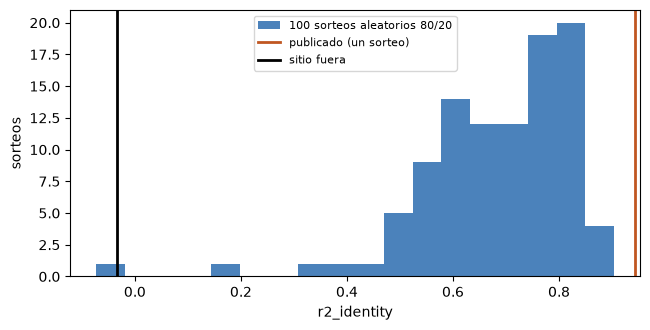

In [5]:
# Un sitio fuera para el brazo de apilamiento, la brecha de protocolo y el histograma
tested, predicted = [], []
for split in bf.leave_one_site_out(train):
    arm = factories["stacking"]().fit(split.train)
    tested += list(split.test)
    predicted += arm.predict(split.test)
held_out = bf.score(tested, predicted).r2_identity
gap = random_median - held_out
print(f"stacking: sitio fuera {held_out:.4f} | brecha de protocolo (mediana aleatoria menos sitio fuera) {gap:.4f}")
print("brecha versionada:", round(benchmark["verdict"]["protocol_gap_random_minus_grouped"]["stacking"], 4))

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.hist(random_scores["stacking"], bins=18, color="#2b6cb0", alpha=0.85, label="100 sorteos aleatorios 80/20")
ax.axvline(bf.PUBLISHED_RANDOM_SPLIT_R2["stacking"], color="#c05621", lw=2, label="publicado (un sorteo)")
ax.axvline(held_out, color="black", lw=2, label="sitio fuera")
ax.set_xlabel("r2_identity")
ax.set_ylabel("sorteos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Estado del arte

- **Sui, Zhou, Zhao, Yang y Zou 2025** (https://doi.org/10.3390/app15031254) ajustan un conjunto de apilamiento de un bosque aleatorio y gradient boosting bajo un metaaprendiz lineal sobre los 97 tiros e informan una varianza explicada de 0,943 en una sola división aleatoria 80/20. La base de investigación del SDD registra que los autores probaron validación cruzada y la quitaron, de modo que la división única es toda la evidencia.
- **Amoako, Jha y Zhong 2022** (https://doi.org/10.3390/mining2020013) ajustan regresores de vectores de soporte con dos núcleos sobre las mismas filas y llegan a la conclusión opuesta sobre el núcleo respecto del estudio de 2025.
- Un remuestreo que ignora la dependencia de los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

El estado del arte para la afirmación "un conjunto aprendido predice la fragmentación en 0,94" es por tanto un único sorteo, sin dispersión y sin campaña fuera.

## Resultados

**La cifra publicada no es un sorteo típico de su propio protocolo.** Para el conjunto de apilamiento los 100 sorteos reproducidos caen bajo 0,943, y el sorteo mediano es mucho menor; para la regresión de núcleo polinómico la mayoría de los sorteos cae bajo la cifra publicada. El número publicado es un sorteo favorable, o un sorteo con otra elección de parámetros, no la esperanza del protocolo. Las medianas y partes del notebook igualan las versionadas.

**Los duplicados no lo explican.** Colapsar los gemelos mueve la mediana del apilamiento en unas milésimas, así que el puntaje alto no son duplicados memorizados.

**La campaña sí.** Con el sitio fuera, el mismo conjunto cae de una mediana cercana a 0,70 a un puntaje cercano a cero, una brecha de protocolo de unos 0,74. El puntaje que informa una división aleatoria mide qué tan bien el modelo interpola entre tiros de campañas que ya vio, que es una pregunta distinta de cómo se comporta en una mina nueva.

**Qué no muestra esto.** No muestra que el 0,943 sea erróneo como afirmación sobre la división de los autores; muestra que es un sorteo de una distribución, y que la distribución responde una pregunta que el profesional no se hace. Tampoco explica por qué: con diez campañas, los puntajes con sitio fuera también son ruidosos, y el notebook siguiente lo pondera.

## Resumen

- Un puntaje publicado es un sorteo; el motor lo ubica en 100 sorteos de su propio protocolo, y 0,943 queda sobre todos ellos para el conjunto de apilamiento.
- Los vectores de entrada duplicados no explican la brecha; la campaña compartida sí.
- La brecha entre una división aleatoria y una campaña fuera es de unos 0,74 para este brazo.
- Siguiente: el notebook 04 muestra la brecha en todos los brazos aprendidos y por qué el protocolo es la afirmación del producto más allá del estado del arte (nivel 4).

## Referencias

- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el conjunto de apilamiento, 0,943, 0,578)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte sobre las mismas filas)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (dependencia en la validación cruzada)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/